In [3]:
import pandas as pd
import numpy as np

np.random.seed(42)

n = 100
study_hours = np.random.normal(5, 2, n)
attendance = np.random.normal(85, 10, n)
previous_mark = np.random.normal(70, 15, n)
final_score = (0.5 * study_hours) + (0.3 * attendance) + (0.2 * previous_mark) + np.random.normal(0, 5, n)
df = pd.DataFrame({
'study_hours': study_hours,
'attendance': attendance,
'previous_mark': previous_mark,
'final_score': final_score
})

df.loc[0:5, 'study_hours'] = np.nan # Missing values
df.loc[99, 'study_hours'] = 50 # Outlier
df.loc[98, 'attendance'] = -10 # Impossible value

print(df)
df.to_csv('student_data.csv', index=False)

    study_hours  attendance  previous_mark  final_score
0           NaN   70.846293      75.366810    35.178989
1           NaN   80.793547      78.411768    39.481248
2           NaN   81.572855      86.245769    48.605167
3           NaN   76.977227      85.807031    47.329456
4           NaN   83.387143      49.334959    37.044473
..          ...         ...            ...          ...
95     2.072970   88.853174      59.606356    37.267830
96     5.592241   76.161426      83.493998    33.777675
97     5.522111   86.537251      74.609493    50.413491
98     5.010227  -10.000000      82.192932    44.045627
99    50.000000   73.570297      79.444433    46.414470

[100 rows x 4 columns]


For the null values i have replaced it with the median of the data because there is a data that is very huge which makes the mean very large so i have decided to take the median 

In [4]:
study_hours_median = df['study_hours'].median()
df['study_hours'] = df['study_hours'].fillna(study_hours_median)

In the study hours and attendance columns  there are values that are negative which is unrealistic so i have removed the entire row 
For the study hour data with value 50, i have take the measure to replace it a realistic value, even though removing it is an option but it is not the better one 

In [5]:
df = df[(df['study_hours'] >= 0)]
df = df[(df['attendance'] >= 0)]
df.loc[df['study_hours'] > 14, 'study_hours'] = 14.0

In [18]:
print(df)

    study_hours  attendance  previous_mark  final_score
0      4.812342   70.846293      75.366810    35.178989
1      4.812342   80.793547      78.411768    39.481248
2      4.812342   81.572855      86.245769    48.605167
3      4.812342   76.977227      85.807031    47.329456
4      4.812342   83.387143      49.334959    37.044473
..          ...         ...            ...          ...
94     4.215784   86.731809      75.355232    49.095682
95     2.072970   88.853174      59.606356    37.267830
96     5.592241   76.161426      83.493998    33.777675
97     5.522111   86.537251      74.609493    50.413491
99    14.000000   73.570297      79.444433    46.414470

[98 rows x 4 columns]


In [9]:
X = df[['study_hours', 'attendance', 'previous_mark']]
y = df['final_score']
print(X.shape, y.shape)  
print(df.dtypes)

(98, 3) (98,)
study_hours      float64
attendance       float64
previous_mark    float64
final_score      float64
dtype: object


Feature matrix: 98 × 3 after cleaning (originally 100 × 3).
Numerical columns: all four (study_hours, attendance, previous_mark, final_score).
Target variable: final_score.

In [6]:
summary = df.agg(['mean', 'median', 'std']).T
print(summary.round(2))

                mean  median    std
study_hours     4.88    4.81   1.95
attendance     85.19   85.84   9.63
previous_mark  71.02   71.47  16.31
final_score    42.62   42.56   6.12


Mean ≈ median in every column (e.g. final_score 42.62 vs 42.56). The distributions are roughly symmetric, with no strong skew after cleaning.
previous_mark has the largest spread (std 16.31), so students’ earlier performance varies a lot. study_hours has the smallest (std 1.95), so most students study a similar amount.
final_score is centred around 42.6 with a std of 6.1, which is lower than previous_mark and attendance. The columns are on very different scales (study_hours around 5 vs previous_mark around 71), which matters in Part F.

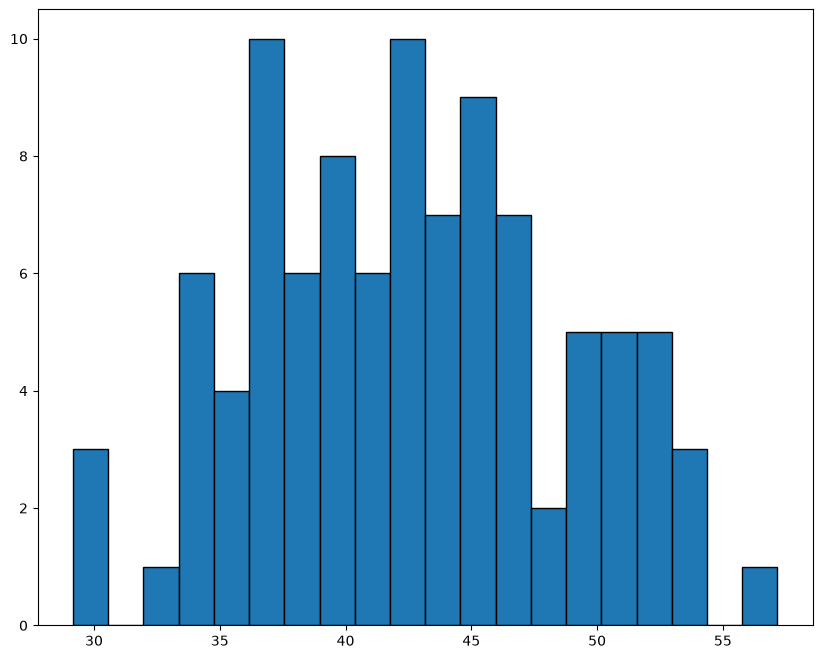

In [7]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 8))
plt.hist(df['final_score'],bins=20, edgecolor='black', alpha=1)
plt.show()

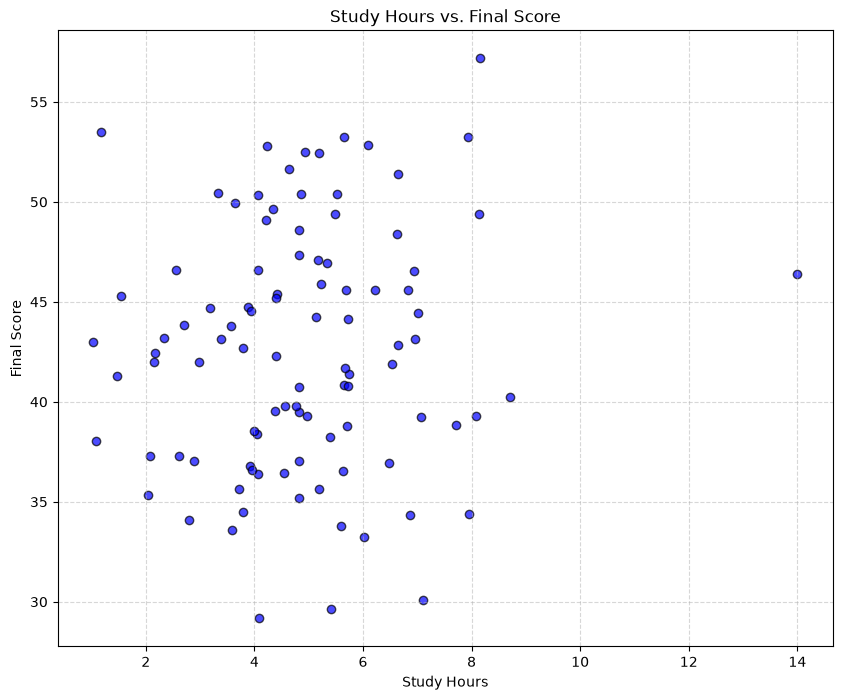

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))
plt.scatter(df['study_hours'], df['final_score'], color='blue', edgecolors='black', alpha=0.7)

plt.title('Study Hours vs. Final Score')
plt.xlabel('Study Hours')
plt.ylabel('Final Score')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [10]:
r = df['study_hours'].corr(df['final_score'])
print(round(r, 3))

0.099


Critical thinking:


No, the correlation does not guarantee a specific score. Correlation describes an average 
tendency across students, not a prediction for one student. With r this low, two students
 who both study 10 hours can end up with very different scores.
Lurking/confounding variable: prior ability or motivation (previous_mark is one measurable form of it). 
Strong or motivated students may both study more and score higher, so study time may not be the cause. Other candidates are attendance, sleep, or teaching quality.

In [11]:
x = df[['study_hours', 'attendance', 'previous_mark']].iloc[0].values
w = np.array([0.5, 0.2, 0.4])
b = 5

y_hat = np.dot(w, x) + b
print(y_hat)

51.72215347600458


Conceptual answers:

w is the weight vector. Each weight says how much its feature contributes to the predicted score (here study_hours counts 0.5 per hour, attendance 0.2, previous_mark 0.4). 
A larger weight means the feature has more influence. Training a model means finding the best weights.
b is the bias (intercept). It is the baseline prediction when all features are zero. 
Without it the model’s line would be forced through the origin, so it couldn’t shift to fit the data’s overall level.

In [12]:
for col in ['study_hours', 'previous_mark']:
    df[col + '_scaled'] = (df[col] - df[col].mean()) / df[col].std()

print(df[['study_hours_scaled', 'previous_mark_scaled']].describe().round(2))

       study_hours_scaled  previous_mark_scaled
count               98.00                 98.00
mean                -0.00                  0.00
std                  1.00                  1.00
min                 -1.97                 -3.04
25%                 -0.55                 -0.66
50%                 -0.04                  0.03
75%                  0.43                  0.57
max                  4.66                  3.48


KNN measures similarity with distance (usually Euclidean). study_hours ranges roughly from 1 to 14, while previous_mark ranges from about 30 to over 100, 
with a standard deviation of 16 vs about 2. A 10-point difference in previous_mark is a small change for a student, but it adds far more to the distance 
than a 2-hour difference in study_hours, which is a big change. So previous_mark would dominate the distance calculation and study_hours would be almost 
ignored. Standardizing puts both features on the same scale, so each contributes fairly.